# NASA PROFILE

In [2]:
# Import the module
import process_airspace
import pandas as pd

# Specify the input file path and output directory
input_file_path = 'data/IFF_ZOB_20231222_050004_86382_LADDfiltered.csv'
output_dir = 'output'

# Call the function to process the file
csv_file_path, unique_acid_file_path = process_airspace.process_airspace_file(input_file_path, output_dir)

# Now you can use the generated CSV file in your notebook
print(f"Filtered rows saved to: {csv_file_path}")
print(f"Unique acId list saved to: {unique_acid_file_path}")

# Read the generated CSV file
filtered_rows = pd.read_csv(csv_file_path)
print(filtered_rows.head())



Filtered rows saved to: output/filtered_rows.csv
Unique acId list saved to: output/unique_acid_list.csv


/var/folders/zp/d0v8jch51xj1cyjpyh_xlfy80000gn/T/ipykernel_3609/2704840506.py:17: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_rows = pd.read_csv(csv_file_path)


   recType                  recTime  fltKey  bcnCode  cid Source  msgType  \
0        3  2023-12-22 04:10:48.000   13061   7417.0  380    ZOB  TH_FIXM   
1        3  2023-12-22 04:10:58.000   13061   7417.0  380    ZOB  TH_FIXM   
2        3  2023-12-22 04:11:13.000   13061   7417.0  380    ZOB  TH_FIXM   
3        3  2023-12-22 04:11:22.000   13061   7417.0  380    ZOB  TH_FIXM   
4        3  2023-12-22 04:11:36.000   13061   7417.0  380    ZOB  TH_FIXM   

      acId  recTypeCat    coord1  ...  opsType  airportCode  trackNumber  \
0  ACA7045           1  42.88167  ...      NaN          NaN          NaN   
1  ACA7045           1  42.87194  ...      NaN          NaN          NaN   
2  ACA7045           1  42.85722  ...      NaN          NaN          NaN   
3  ACA7045           1  42.84722  ...      NaN          NaN          NaN   
4  ACA7045           1  42.83194  ...      NaN          NaN          NaN   

   tptReturnType  modeSCode  sensorTrackNumberList  spi  dvs  dupM3a  tid  
0   

# Departure and Arrival Airport（BTS Data）

In [17]:
import subprocess
import os
import pandas as pd

# Specify the parameters
file_path_ua = 'data/T_ONTIME_MARKETING-8.csv'
filtered_rows_path = 'output/filtered_rows.csv'
icao_iata_mapping_path = 'data/icao_iata_codes.csv'
output_dir = 'output'

# Call the process_airlines.py script
subprocess.run(['python', 'process_airlines.py', file_path_ua, filtered_rows_path, icao_iata_mapping_path, output_dir])

# Now you can use the generated CSV files in your notebook
merged_csv_path = os.path.join(output_dir, 'merged_unique_data.csv')
unmatched_csv_path = os.path.join(output_dir, 'unmatched_iata.csv')

print(f"Merged unique data saved to: {merged_csv_path}")
print(f"Unmatched IATA codes saved to: {unmatched_csv_path}")

# Read the generated CSV files
merged_data = pd.read_csv(merged_csv_path)
unmatched_iata = pd.read_csv(unmatched_csv_path)

print("Merged Data:")
print(merged_data.head())

print("Unmatched IATA codes:")
print(unmatched_iata)


/Users/hoo/Desktop/UMICH/FAA/process_airlines.py:7: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_rows = pd.read_csv(filtered_rows_path)


Total entries in merged_data: 3946
NaN entries in last column (DEST_CITY_NAME): 1705
NaN ratio: 43.21%
Merged Data:
       acId Carrier FlightNumber  ... ORIGIN_CITY_NAME DEST DEST_CITY_NAME
0   ACA7045     ACA         7045  ...              NaN  NaN            NaN
1    MXY527     MXY          527  ...              NaN  NaN            NaN
2   UAL1774     UAL         1774  ...      Chicago, IL  EWR     Newark, NJ
33   SWG683     SWG          683  ...              NaN  NaN            NaN
34  FFT3987     FFT         3987  ...      Orlando, FL  DTW    Detroit, MI

[5 rows x 8 columns]
Unmatched IATA codes:
Empty DataFrame
Columns: [acId, Carrier, FlightNumber, IATA]
Index: []
Merged unique data saved to: output/merged_unique_data.csv
Unmatched IATA codes saved to: output/unmatched_iata.csv
Merged Data:
      acId Carrier  FlightNumber IATA ORIGIN ORIGIN_CITY_NAME DEST  \
0  ACA7045     ACA        7045.0   AC    NaN              NaN  NaN   
1   MXY527     MXY         527.0   MX    NaN      

In [5]:
import subprocess

# Specify the airline ID and input directory
airline_id = 'UAL1774'
input_dir = 'output'

# Call the Python script to get airline info
result = subprocess.run(['python', 'get_airline_info.py', airline_id, input_dir], capture_output=True, text=True)

# Print the output
print(result.stdout)


Departure: ORD
Arrival: EWR



# Regions Across Time

In [14]:
import os
import subprocess
import pandas as pd

# Specify the input file path and output directory
filtered_rows_path = 'output/filtered_rows.csv'
output_dir = 'output'

# Call the flight_region.py script
subprocess.run(['python', 'flight_region.py', filtered_rows_path, output_dir])

# Now you can use the generated CSV file in your notebook
organized_flights_path = os.path.join(output_dir, 'organized_flights.csv')
print(f"Organized flights saved to: {organized_flights_path}")

# Read the generated CSV file
organized_flights = pd.read_csv(organized_flights_path)
print(organized_flights.head())



/Users/hoo/Desktop/UMICH/FAA/flight_region.py:64: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_rows = pd.read_csv(filtered_rows_path)
/Users/hoo/Desktop/UMICH/FAA/flight_region.py:106: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result = result.append({'Aircraft ID': ac_id, 'Locations': locations, 'Durations': durations}, ignore_index=True)
/Users/hoo/Desktop/UMICH/FAA/flight_region.py:106: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result = result.append({'Aircraft ID': ac_id, 'Locations': locations, 'Durations': durations}, ignore_index=True)
/Users/hoo/Desktop/UMICH/FAA/flight_region.py:106: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result = resu

Organized flights saved to: output/organized_flights.csv
Organized flights saved to: output/organized_flights.csv
  Aircraft ID                                          Locations  \
0        AAL1              ['BLUFFTON', 'CLARKSBURG', 'RAVENNA']   
1     AAL1020                            ['BLUFFTON', 'DETROIT']   
2     AAL1029                          ['ALLEGHENY', 'FRANKLIN']   
3     AAL1111  ['CLARKSBURG', 'FRANKLIN', 'JAMESTOWN', 'NIAGA...   
4     AAL1169                  ['BLUFFTON', 'DETROIT', 'HUDSON']   

                                           Durations  
0  ['0 days 00:12:54', '0 days 00:19:06', '0 days...  
1             ['0 days 00:09:35', '0 days 00:06:03']  
2             ['0 days 00:09:00', '0 days 00:15:21']  
3  ['0 days 00:06:57', '0 days 00:06:26', '0 days...  
4  ['0 days 00:05:16', '0 days 00:06:41', '0 days...  


# Tail Number And Paired Flight

In [22]:
import os
import subprocess
import pandas as pd

# Specify the parameters
file_path_ua = 'data/T_ONTIME_MARKETING-8.csv'
tail_number = 'N442UA'
airports = 'DTW,FNT,TOL,CLE,PIT,BUF,ROC,CMH'
output_dir = 'output'

# Ensure the output directory exists
os.makedirs(output_dir, exist_ok=True)

# Call the process_flights.py script
subprocess.run(['python', 'process_flights.py', file_path_ua, tail_number, airports, output_dir])

# Now you can use the generated CSV file in your notebook
output_file_name = f'{tail_number}_flights.csv'
output_file_path = os.path.join(output_dir, output_file_name)
print(f"Organized flights saved to: {output_file_path}")

# Read the generated CSV file
organized_flights = pd.read_csv(output_file_path)
print(organized_flights.head())


Organized flights saved to: output/N442UA_flights.csv
  2023-12-01, N442UA, ['UA1889', 'UA302', 'UA726'], ['1:02', '1:06']
0                  2023-12-02, N442UA, ['UA738'], []                
1  2023-12-04, N442UA, ['UA1889', 'UA302'], ['0:59']                
2  2023-12-07, N442UA, ['UA1753', 'UA2337'], ['0:...                
3                  2023-12-17, N442UA, ['UA299'], []                
4  2023-12-18, N442UA, ['UA454', 'UA2460', 'UA126...                


/Users/hoo/Desktop/UMICH/FAA/process_flights.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tail_num_data_selected['DEP_TIME'] = tail_num_data_selected['DEP_TIME'].apply(convert_time)
/Users/hoo/Desktop/UMICH/FAA/process_flights.py:45: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tail_num_data_selected['ARR_TIME'] = tail_num_data_selected['ARR_TIME'].apply(convert_time)
/Users/hoo/Desktop/UMICH/FAA/process_flights.py:48: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a

# Visualistion

/Users/hoo/Desktop/UMICH/FAA/plot_flight_tracks.py:61: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_rows = pd.read_csv(filtered_rows_path)


Flight tracks saved to: output/flight_tracks.png


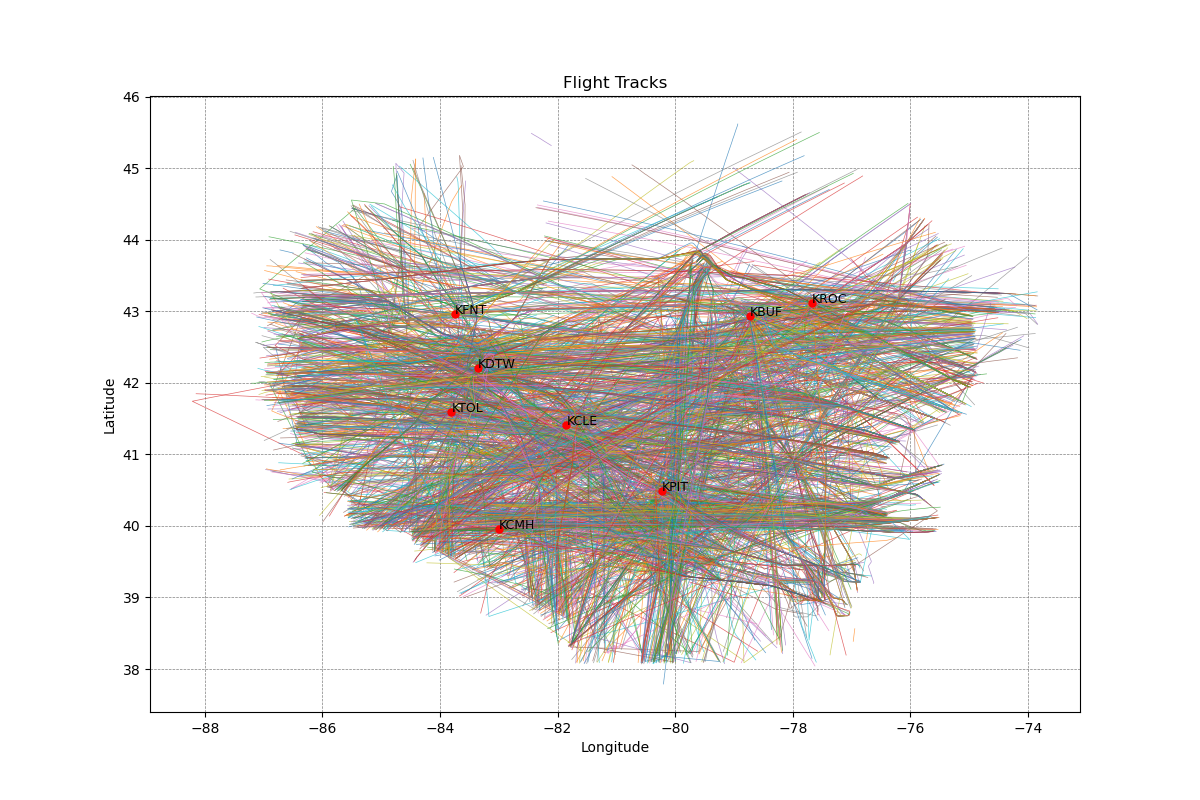

In [21]:
import subprocess
import os

# Specify the paths
filtered_rows_path = 'output/filtered_rows.csv'
output_dir = 'output'
output_image_path = os.path.join(output_dir, 'flight_tracks.png')

# Ensure the output directory exists
os.makedirs(output_dir, exist_ok=True)

# Run the script to plot flight tracks
subprocess.run(['python', 'plot_flight_tracks.py', filtered_rows_path, output_image_path])

# Display the saved image
from IPython.display import Image
Image(filename=output_image_path)



/Users/hoo/Desktop/UMICH/FAA/plot_arrival_airports.py:12: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_rows = pd.read_csv(filtered_rows_path)


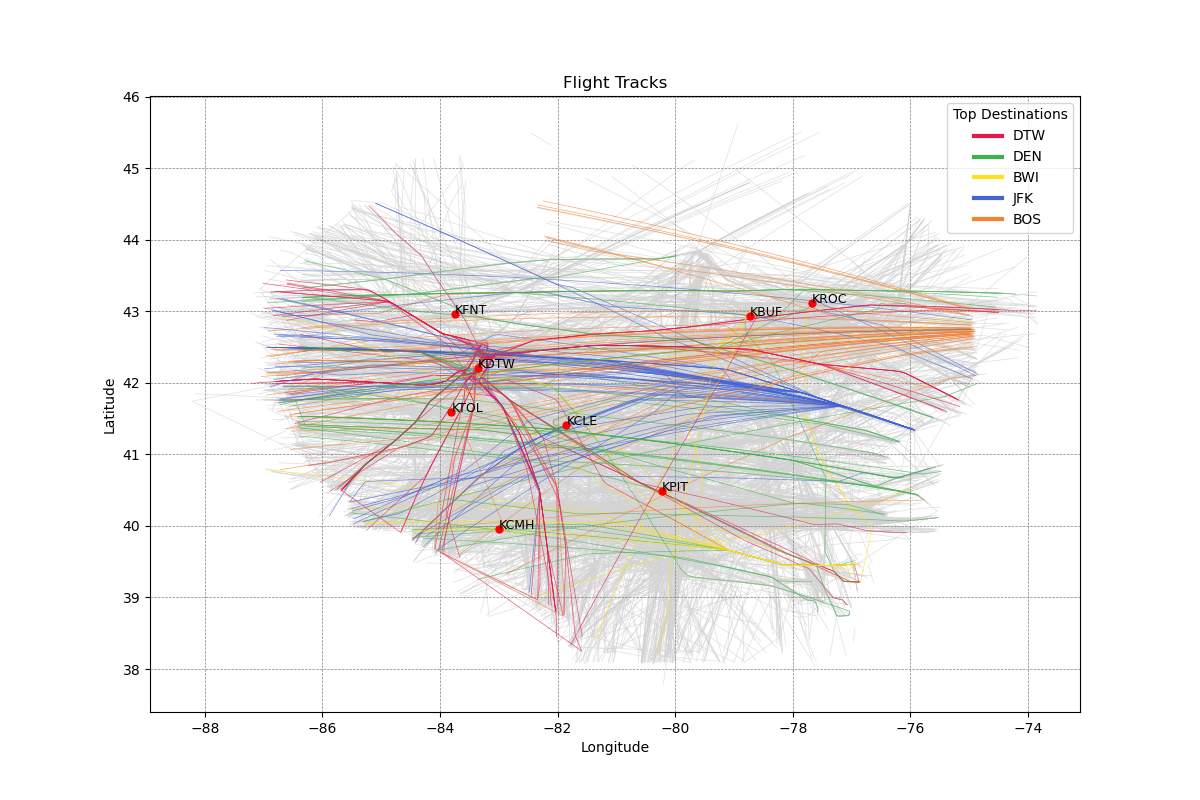

In [23]:
import subprocess
import os

# Define input and output directories
input_dir = 'data'
output_dir = 'output'

# Call the plot_arrival_airports.py script
subprocess.run(['python', 'plot_arrival_airports.py', input_dir, output_dir])

# Define the path to the output image
output_image_path = os.path.join(output_dir, 'arrival_airports.png')

# Display the saved image
from IPython.display import Image
Image(filename=output_image_path)


In [6]:


import plot_region_track
import pandas as pd


filtered_rows_path = 'output/filtered_rows.csv'
filtered_rows = pd.read_csv(filtered_rows_path)

plane_id = 'MXY527' 
output_path = f'output/flight_tracks_{plane_id}.png'

plot_region_track.plot_region_track(filtered_rows, plane_id, output_path)



/var/folders/zp/d0v8jch51xj1cyjpyh_xlfy80000gn/T/ipykernel_5594/2475258261.py:6: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_rows = pd.read_csv(filtered_rows_path)
